# Project: Time Series

## Project Description

A taxi company wants to optimize the work of drivers during rush hours. The tasks are:
- Predict the number of taxi orders for the next hour.
- Build a model for this prediction.
- The *RMSE* metric on the test set must not exceed 48.

### Project Instructions

1. Load the data and resample it by one hour.
2. Analyze the data.
3. Train different models with different hyperparameters. Make the test set 20% of the original data.
4. Check the models on the test set and draw conclusions.

### Data Description

The data is stored in the file `taxi.csv`. The number of orders is in the column '*num_orders*'.

**Plan:**
- 1. Data preparation
- 2. Data analysis
- 3. Model training
- 4. Model testing
- 5. Conclusions

# 1. Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

Load the data and print the first rows. Use `info()` to check the table structure: data types, number of rows and columns, missing values.

In [2]:
taxi = pd.read_csv('taxi.csv', index_col='datetime', parse_dates=[0])

In [3]:
taxi.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [4]:
taxi.shape

(26496, 1)

Resample the data by one hour. The task is to predict the number of taxi orders for the next hour, so the values are aggregated as sums.

In [5]:
taxi = taxi.sort_index()
taxi = taxi.resample('1H').sum()

In [6]:
f"Time span of the data: {taxi.index.min()} - {taxi.index.max()}"

'Time span of the data: 2018-03-01 00:00:00 - 2018-08-31 23:00:00'

# 2. Analysis

Decompose the data into three components: trend, seasonality and residuals. Plot the last month of the time series and analyze it.

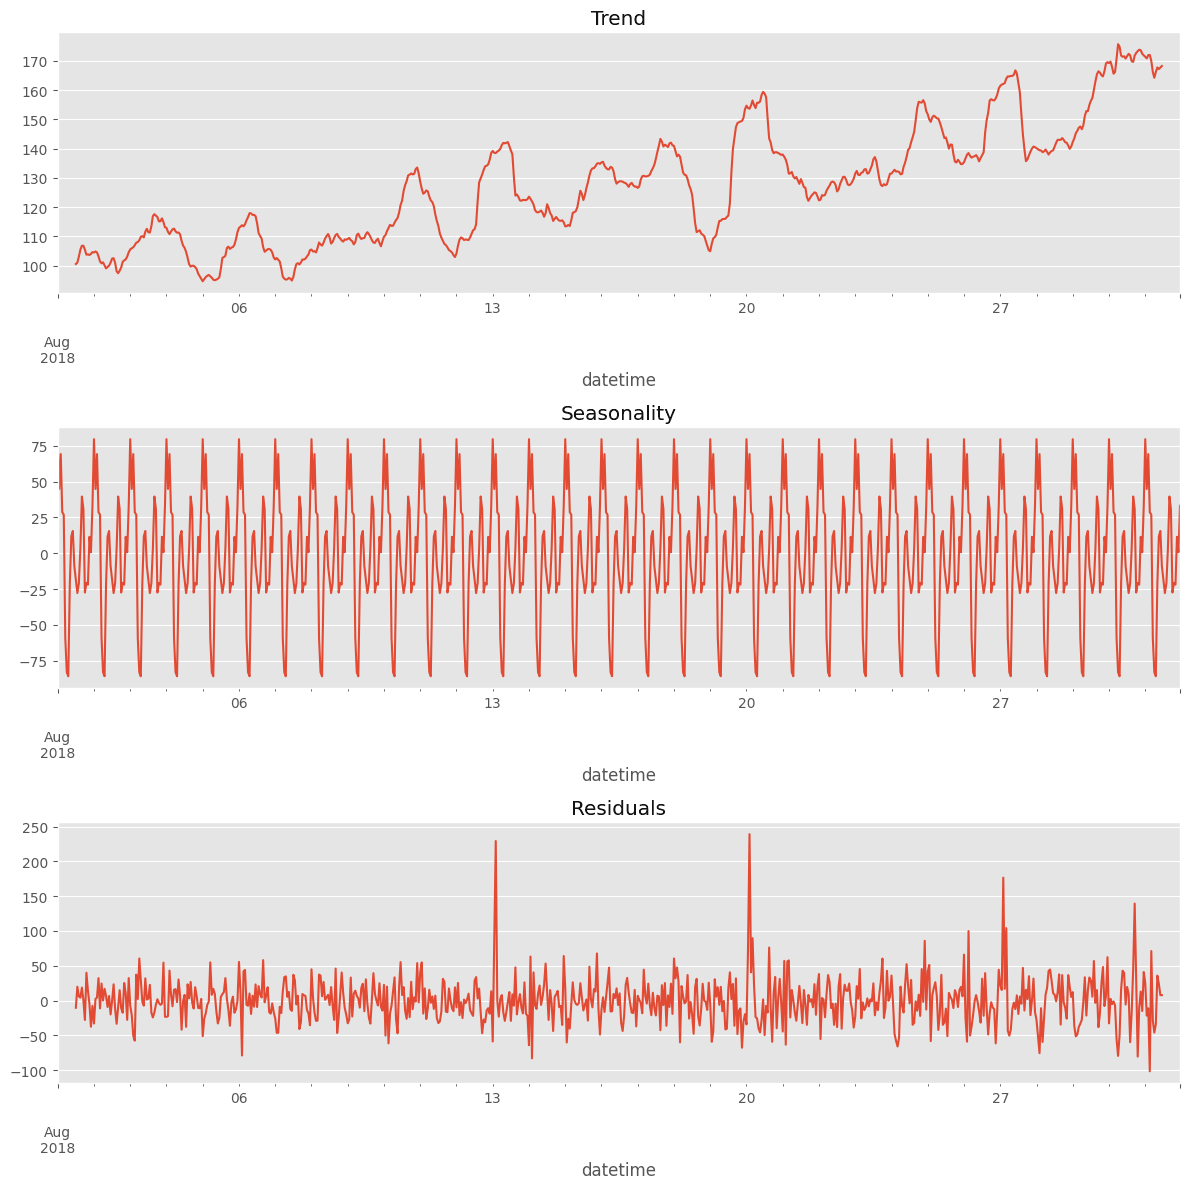

In [7]:
plt.style.use('ggplot')
decomposed = seasonal_decompose(taxi['2018-08':'2018-08'])
plt.figure(figsize=(12, 12))
plt.subplot(311)

decomposed.trend.plot(ax=plt.gca())
plt.title('Trend')
plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())

plt.title('Seasonality')
plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())

plt.title('Residuals')
plt.tight_layout()

- The seasonal part looks static within a day. There are almost no taxi orders at night, and the peak is closer to the evening.
- The residuals also have a constant mean, but large spikes appear periodically (explained by higher demand for taxis on weekends and holidays).
- The trend shows a linear growth in the number of orders over time. Build the trend for the whole time series to see the full picture.

Text(0.5, 1.0, 'Trend')

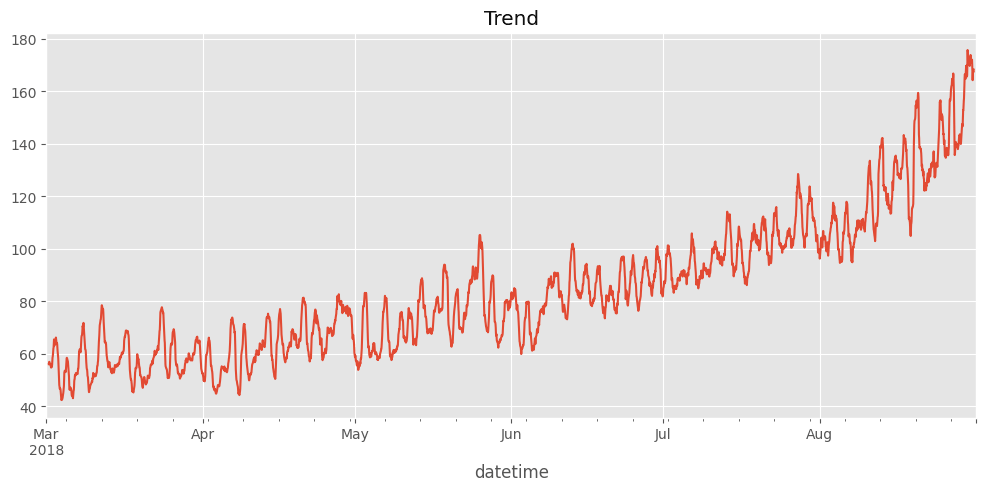

In [8]:
plt.style.use('ggplot')
decomposed = seasonal_decompose(taxi)
plt.figure(figsize=(12, 5))
decomposed.trend.plot(ax=plt.gca())
plt.title('Trend')

- The trend has a more complex dependency on time (quadratic or exponential, hard to say from this sample). For this task it is treated as linear, since predictions are needed only one hour ahead.
- The trend line is also noisy. A moving average with a window of several tens of hours may be needed for prediction.

# 3. Training

The baseline model predicts each new value with the previous one.

In [9]:
train, test = train_test_split(taxi, shuffle=False, test_size=0.2)
train = train.dropna()
pred_previous = test.shift()
pred_previous.iloc[0] = train.iloc[-1]
rmse_base =  mean_squared_error(test['num_orders'], pred_previous) ** 0.5
print("RMSE of the baseline model:", round(rmse_base, 3))

RMSE of the baseline model: 53.368


Check the prediction by the mean value.

In [10]:
pred_mean = np.ones(test.shape) * train['num_orders'].mean()
print("RMSE of the mean value prediction:", mean_squared_error(test['num_orders'], pred_mean) ** 0.5)

RMSE of the mean value prediction: 74.42015786913375


Predicting by the previous value gives a better result, so it is used as the baseline.

Write a function that creates the training features: `dayofweek`, the moving average `rolling_mean` (with window size `rolling_mean_size`), and the lag features `lag_i`.

In [11]:
def make_features(data, max_lag, rolling_mean_size):
    df = data.copy()
    df['dayofweek'] = df.index.dayofweek
    
    for lag in range(1, max_lag + 1):
        df['lag_{}'.format(lag)] = df['num_orders'].shift(lag)

    df['rolling_mean'] = df['num_orders'].shift().rolling(rolling_mean_size).mean()
    
    return df

In [12]:
df = make_features(taxi, 30, 50)

Train a linear regression first. Split the data 80/20 (20% test set).

In [13]:
train, test = train_test_split(df, shuffle=False, test_size=0.2)
train = train.dropna()

In [14]:
train.head(10)

,num_orders,dayofweek,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,...,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_30,rolling_mean
datetime,,,,,,,,,,,,,,,,,,,,,
2018-03-03 02:00:00,25,5,108.0,163.0,72.0,119.0,101.0,93.0,49.0,89.0,...,20.0,64.0,75.0,120.0,90.0,58.0,113.0,66.0,61.0,62.82
2018-03-03 03:00:00,64,5,25.0,108.0,163.0,72.0,119.0,101.0,93.0,49.0,...,11.0,20.0,64.0,75.0,120.0,90.0,58.0,113.0,66.0,60.84
2018-03-03 04:00:00,44,5,64.0,25.0,108.0,163.0,72.0,119.0,101.0,93.0,...,11.0,11.0,20.0,64.0,75.0,120.0,90.0,58.0,113.0,60.42
2018-03-03 05:00:00,15,5,44.0,64.0,25.0,108.0,163.0,72.0,119.0,101.0,...,7.0,11.0,11.0,20.0,64.0,75.0,120.0,90.0,58.0,59.88
2018-03-03 06:00:00,9,5,15.0,44.0,64.0,25.0,108.0,163.0,72.0,119.0,...,46.0,7.0,11.0,11.0,20.0,64.0,75.0,120.0,90.0,58.86
2018-03-03 07:00:00,17,5,9.0,15.0,44.0,64.0,25.0,108.0,163.0,72.0,...,45.0,46.0,7.0,11.0,11.0,20.0,64.0,75.0,120.0,58.18
2018-03-03 08:00:00,56,5,17.0,9.0,15.0,44.0,64.0,25.0,108.0,163.0,...,54.0,45.0,46.0,7.0,11.0,11.0,20.0,64.0,75.0,58.40
2018-03-03 09:00:00,73,5,56.0,17.0,9.0,15.0,44.0,64.0,25.0,108.0,...,91.0,54.0,45.0,46.0,7.0,11.0,11.0,20.0,64.0,59.28
2018-03-03 10:00:00,52,5,73.0,56.0,17.0,9.0,15.0,44.0,64.0,25.0,...,36.0,91.0,54.0,45.0,46.0,7.0,11.0,11.0,20.0,60.44


In [15]:
X_train = train.drop('num_orders', axis = 1)
y_train = train['num_orders']
X_test = test.drop('num_orders', axis = 1)
y_test = test['num_orders']

lm = LinearRegression()
lm.fit(X_train, y_train)
preds_train = lm.predict(X_train)
print("RMSE on the training set:", mean_squared_error(y_train, preds_train) ** 0.5)

preds_test = lm.predict(X_test)
print("RMSE on the test set:    ", mean_squared_error(y_test, preds_test) ** 0.5)

RMSE on the training set: 24.107441665527308
RMSE on the test set:     39.82156637969243


Tune the parameters of the linear regression more precisely.

In [16]:
%%time
best_lag_lm = 0
best_roll_size_lm = 0
best_rmse_lm = 48
for lag in range(1, 101, 5):
    for roll_size in range(1, 101, 5):

        df = make_features(taxi, lag, roll_size)
        train, test = train_test_split(df, shuffle=False, test_size=0.2)
        train = train.dropna()
        X_train = train.drop('num_orders', axis = 1)
        y_train = train['num_orders']
        X_test = test.drop('num_orders', axis = 1)
        y_test = test['num_orders']

        lm = LinearRegression()
        lm.fit(X_train, y_train)

        preds_test = lm.predict(X_test)
        rmse = mean_squared_error(y_test, preds_test) ** 0.5
        if rmse < best_rmse_lm :
            best_rmse_lm = rmse
            best_lag_lm = lag
            best_roll_size_lm = roll_size

print(f"RMSE on the test set: {best_rmse_lm}, max lag {best_lag_lm}, rolling window size {best_roll_size_lm}")

RMSE on the test set: 35.69378463494806, max lag 96, rolling window size 96
CPU times: user 11.5 s, sys: 6.63 s, total: 18.1 s
Wall time: 9.3 s


- Try a model with regularization, for example Lasso with L1 regularization.

In [17]:
def model_build(model):
    best_lag = 0
    best_roll_size = 0
    best_alpha = 0
    best_rmse = 48
    for lag in range(1, 101, 5):
        for roll_size in range(1, 101, 5):
            for alpha in np.arange(0.1, 1, 0.2):

                df = make_features(taxi, lag, roll_size)
                train, test = train_test_split(df, shuffle=False, test_size=0.2)
                train = train.dropna()
                X_train = train.drop('num_orders', axis = 1)
                y_train = train['num_orders']
                X_test = test.drop('num_orders', axis = 1)
                y_test = test['num_orders']
                
                if model == 'Lasso' :
                    lm = Lasso(alpha=alpha)
                elif model == 'Ridge' :
                    lm = Ridge(alpha=alpha)
                lm.fit(X_train, y_train)

                preds_test = lm.predict(X_test)
                rmse = mean_squared_error(y_test, preds_test) ** 0.5
                if rmse < best_rmse :
                    best_rmse = rmse
                    best_lag = lag
                    best_roll_size = roll_size
                    best_alpha = alpha
    return best_rmse, best_lag, best_roll_size, best_alpha


In [18]:
%%time
best_rmse_ls, best_lag_ls, best_roll_size_ls, best_alpha_ls = model_build("Lasso")
print(f"===== Lasso model =====")
print(f"RMSE on the test set: {best_rmse_ls}, max lag {best_lag_ls}, rolling window size {best_roll_size_ls}")
print(f"Regularization coefficient: {best_alpha_ls}")

===== Lasso model =====
RMSE on the test set: 35.67281060216996, max lag 96, rolling window size 41
Regularization coefficient: 0.9000000000000001
CPU times: user 1min 45s, sys: 1min, total: 2min 45s
Wall time: 1min 25s


In [19]:
%%time
best_rmse_rg, best_lag_rg, best_roll_size_rg, best_alpha_rg = model_build("Ridge")
print(f"===== Ridge model =====")
print(f"RMSE on the test set: {best_rmse_rg}, max lag {best_lag_rg}, rolling window size {best_roll_size_rg}")
print(f"Regularization coefficient: {best_alpha_rg}")

===== Ridge model =====
RMSE on the test set: 35.694169666362185, max lag 96, rolling window size 1
Regularization coefficient: 0.1
CPU times: user 47.9 s, sys: 27.3 s, total: 1min 15s
Wall time: 38.6 s


# 4. Testing

The test set check was done in the previous step. Collect the results in a table and analyze them.

In [20]:
stats = pd.DataFrame([['Baseline', round(rmse_base, 3), 1, 0, np.nan],
                      ['Linear Regression', round(best_rmse_lm, 3), best_lag_lm, best_roll_size_lm, np.nan],
                      ['Lasso', round(best_rmse_ls, 3), best_lag_ls, best_roll_size_ls, best_alpha_ls],
                      ['Ridge', round(best_rmse_rg, 3), best_lag_rg, best_roll_size_rg, best_alpha_rg]],
                    columns = ['model', 'rmse', 'max_lag', 'roll_size', 'alpha'])

In [21]:
stats

,model,rmse,max_lag,roll_size,alpha
0,Baseline,53.368,1,0,NaN
1,Linear Regression,35.694,96,96,NaN
2,Lasso,35.673,96,41,0.9
3,Ridge,35.694,96,1,0.1


For the Lasso model with the regularization parameter alpha=0.9, plot the target and the predictions against time. Check when the model was more and less accurate. Only the last 10 days are plotted for readability.

In [22]:
df = make_features(taxi, 96, 41)
train, test = train_test_split(df, shuffle=False, test_size=0.2)
train = train.dropna()
X_train = train.drop('num_orders', axis = 1)
y_train = train['num_orders']
X_test = test.drop('num_orders', axis = 1)
y_test = test['num_orders']

lasso = Lasso(alpha=0.9)
lasso.fit(X_train, y_train)
preds_test = pd.Series(lasso.predict(X_test), index = y_test.index, name='preds')

In [23]:
df_preds = pd.concat([y_test, preds_test], axis=1)
df_preds.head(10)

,num_orders,preds
datetime,,
2018-07-26 04:00:00,131,127.387869
2018-07-26 05:00:00,83,75.378455
2018-07-26 06:00:00,21,48.722166
2018-07-26 07:00:00,39,65.843009
2018-07-26 08:00:00,80,61.754457
2018-07-26 09:00:00,138,109.017315
2018-07-26 10:00:00,142,92.892337
2018-07-26 11:00:00,86,107.615540
2018-07-26 12:00:00,102,114.649062


<Axes: xlabel='datetime', ylabel='num_orders'>

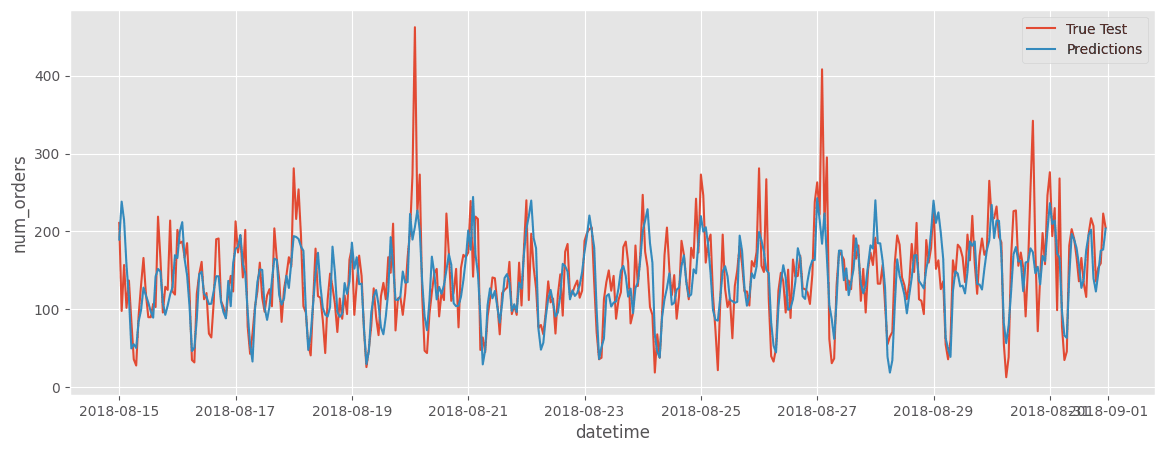

In [24]:
plt.figure(figsize=(14, 5))
plt.style.use('ggplot')
data = df_preds['2018-08-15':]
sns.lineplot(x=data.index, y=data['num_orders'], label='True Test')
sns.lineplot(x=data.index, y=data['preds'], label='Predictions')

- The plot shows that the model predicts the daily repeating pattern quite accurately. It cannot predict the rare spikes in the data (probably higher demand for taxis on weekends). A "day off" feature could help.

# Conclusions

- All linear models give a similar RMSE.
- The maximum lag is limited to 100 because of the model complexity. The RMSE does not improve much beyond it.
- As expected, the best result is given by a rolling window of about 40-50 hours (roughly two days). This value smooths the trend curve well, judging by the plot.
- The Lasso model reduced the RMSE by 33% relative to the baseline.
- The plot shows that the model predicts the daily repeating pattern quite accurately. It cannot predict the rare spikes in the data.